# 5 · Optional: write your own simulator of the Pasqal backend

The `pasqal` emulator from notebooks 1–3 is a fixed model: ideal atoms, and only the final shots come back. CUDA-Q's **`dynamics` target** evolves any operator you write, on the GPU with NVIDIA cuDensityMat. In this notebook you build the backend's Hamiltonian yourself, check it against `emulate=True`, and then do what the backend cannot:

1. write the Rydberg Hamiltonian with CUDA-Q operators,
2. reproduce the backend's pulse semantics,
3. compare your simulator with the `pasqal` emulator,
4. watch the blockade over time,
5. add noise with collapse operators.

**CUDA-Q you will use:** the `dynamics` target, operators (`spin`, `number`, `boson`), `evolve` with dimensions, an initial `State`, an integrator, observables and collapse operators.

The CUDA-Q emulator does the same thing in C++: see `rydbergHamiltonian` in [`runtime/common/AnalogRydberg.cpp`](https://github.com/NVIDIA/cuda-quantum/blob/main/runtime/common/AnalogRydberg.cpp).

In [1]:
# Copyright 2026 Pasqal
# SPDX-License-Identifier: Apache-2.0
import itertools
import math
import warnings

warnings.filterwarnings("ignore", message="The CUDA-Q `sample` and `observe`", category=FutureWarning)

import cudaq
from cudaq import RungeKuttaIntegrator, Schedule, ScalarOperator, boson, spin
from cudaq.operators import RydbergHamiltonian, empty, number
import cupy as cp
import matplotlib.pyplot as plt
import numpy as np

C6 = 865723.02e-30  # level 60, as in notebook 1, in rad m⁶ s⁻¹
STEPS = 400  # output points of each evolution
plt.rcParams.update({"figure.figsize": (7, 3.5), "font.size": 11})

## 1. The Hamiltonian as CUDA-Q operators

$$
\frac{H(t)}{\hbar} = \sum_i \frac{\Omega(t)}{2}\left(\cos\phi(t)\,\sigma^x_i + \sin\phi(t)\,\sigma^y_i\right) - \Delta(t)\sum_i n_i + \sum_{i<j}\frac{C_6}{r_{ij}^6}\, n_i n_j
$$

Each term is a product of a coefficient and an operator on one or two atoms (CUDA-Q calls them *degrees of freedom*): `spin.x(i)`, `spin.y(i)` and `number(i)`, the projector on `1` (Rydberg). Time-dependent coefficients are `ScalarOperator`s, as before.

## 2. The backend's pulse semantics

There is one difference from notebook 1. The `pasqal` target evaluated your functions **only at the schedule times** and joined the samples itself. The `dynamics` target calls the coefficients at every integrator step. To get the same pulse as the backend, we write the interpolation ourselves: linear for amplitude and detuning, held for the phase.

In [2]:
def linear(times, values):
    """Return a function that joins the samples linearly, like the target does for Ω and Δ."""
    return lambda t: float(np.interp(t.real, times, values))


def held(times, values):
    """Return a function that holds each sample until the next one, like the target does for φ."""
    return lambda t: values[min(np.searchsorted(times, t.real, side="right"), len(values)) - 1]


def rydberg_operator(sites, times, amplitude, detuning, phase):
    """Build the Rydberg Hamiltonian of the pasqal backend from waveform samples."""
    omega, delta, phi = linear(times, amplitude), linear(times, detuning), held(times, phase)
    drive_x = ScalarOperator(lambda t: 0.5 * omega(t) * math.cos(phi(t)))
    drive_y = ScalarOperator(lambda t: 0.5 * omega(t) * math.sin(phi(t)))
    minus_delta = ScalarOperator(lambda t: -delta(t))
    # Start from empty(): Python's sum starts from 0, a constant term the noisy solver rejects.
    hamiltonian = sum((drive_x * spin.x(i) + drive_y * spin.y(i) + minus_delta * number(i)
                       for i in range(len(sites))), empty())
    for i, j in itertools.combinations(range(len(sites)), 2):
        hamiltonian += C6 / math.dist(sites[i], sites[j]) ** 6 * number(i) * number(j)
    return hamiltonian

## 3. Evolve and compare

`cudaq.evolve` on the `dynamics` target needs more than the analog target did: the dimension of each degree of freedom (2 for an atom), an initial state (all atoms in `0`) and an integrator. The schedule is now the integrator's output grid, so we give it many points. It returns the state itself, not shots, so we get exact probabilities.

Mind the order: in the state vector, atom $i$ is bit $i$ counted from the **least significant** end, so we reverse each binary index to get the backend's atom-order bitstrings.

In [3]:
def simulate(sites, times, amplitude, detuning, phase, steps=STEPS, observables=(), collapse_operators=()):
    """Evolve all atoms from 0 on the dynamics target; use a density matrix when there are collapse operators."""
    size = len(sites)
    ground = cp.zeros(2**size, dtype=cp.complex128)
    ground[0] = 1
    initial = cp.outer(ground, ground.conj()) if collapse_operators else ground
    return cudaq.evolve(
        rydberg_operator(sites, times, amplitude, detuning, phase),
        {i: 2 for i in range(size)},
        Schedule(np.linspace(times[0], times[-1], steps), ["t"]),
        cudaq.State.from_data(initial),
        observables=list(observables),
        collapse_operators=list(collapse_operators),
        store_intermediate_results=cudaq.IntermediateResultSave.EXPECTATION_VALUE if observables else cudaq.IntermediateResultSave.NONE,
        integrator=RungeKuttaIntegrator(),
    )


def probabilities(state, size):
    """Return atom-order bitstring probabilities from a final state vector or density matrix."""
    data = np.asarray(state.to_numpy())
    p = np.real(np.diag(data)) if data.ndim == 2 else np.abs(data) ** 2
    return {format(k, f"0{size}b")[::-1]: float(p[k]) for k in range(2**size)}

A test program that uses every feature: three atoms, a ramped drive, a detuning sweep and two phase jumps.

total variation distance: 0.0062 (sampling noise at 20000 shots: ~0.0100)


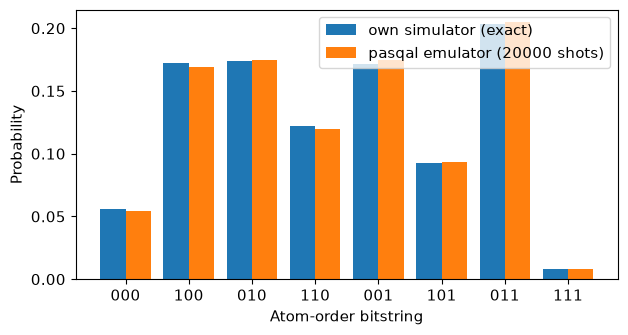

In [4]:
sites = [(0.0, 0.0), (7e-6, 0.0), (3e-6, 6e-6)]
times = [0.0, 0.5e-6, 1.5e-6, 2e-6]
amplitude = [0.0, 2 * np.pi * 1e6, 2 * np.pi * 1e6, 0.0]
detuning = [-6e6, -2e6, 4e6, 8e6]
phase = [0.0, 0.7, 1.3, 1.3]

cudaq.set_target("dynamics")
own = probabilities(simulate(sites, times, amplitude, detuning, phase).final_state(), len(sites))

cudaq.set_target("pasqal", emulate=True, emulation_rydberg_c6=str(C6))
cudaq.set_random_seed(7)
shots = 20000
backend = cudaq.evolve(
    RydbergHamiltonian(atom_sites=sites, amplitude=ScalarOperator(linear(times, amplitude)),
                       phase=ScalarOperator(held(times, phase)), delta_global=ScalarOperator(linear(times, detuning))),
    schedule=Schedule(times, ["t"]), shots_count=shots)
measured = {b: backend.count(b) / shots for b in own}

tvd = sum(abs(own[b] - measured[b]) for b in own) / 2
print(f"total variation distance: {tvd:.4f} (sampling noise at {shots} shots: ~{math.sqrt(len(own) / shots) / 2:.4f})")
x = np.arange(len(own))
plt.bar(x - 0.2, own.values(), width=0.4, label="own simulator (exact)")
plt.bar(x + 0.2, measured.values(), width=0.4, label=f"pasqal emulator ({shots} shots)")
plt.xticks(x, own.keys())
plt.xlabel("Atom-order bitstring")
plt.ylabel("Probability")
plt.legend()
plt.show()

The two agree within sampling noise. Our simulator follows the same model as the backend, including the phase and the bit order.

## 4. Watch the blockade happen

The backend only returns the end of the pulse; to see a curve over time you ran one program per duration (notebook 1, section 5). Here a single evolution stores expectation values at every schedule point. We follow the two atoms of notebook 1, close (5 µm) and far (14 µm), under the same constant drive.

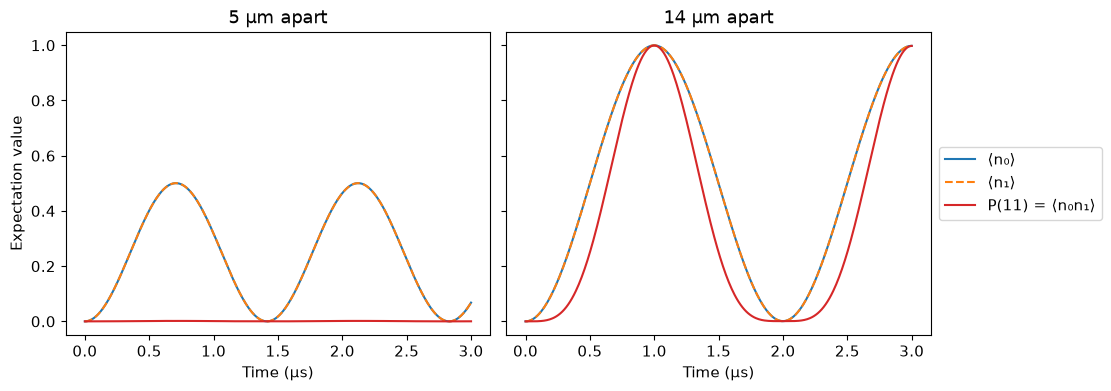

In [5]:
cudaq.set_target("dynamics")
omega = np.pi * 1e6
drive = dict(times=[0.0, 3e-6], amplitude=[omega, omega], detuning=[0.0, 0.0], phase=[0.0, 0.0])
grid = np.linspace(0, 3, STEPS)  # µs, the output points of simulate

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, layout="constrained")
for ax, distance in zip(axes, (5, 14)):
    pair = [(0.0, 0.0), (distance * 1e-6, 0.0)]
    result = simulate(pair, **drive, observables=[number(0), number(1), number(0) * number(1)])
    n0, n1, both = np.array([[e.expectation() for e in step] for step in result.expectation_values()]).T
    ax.plot(grid, n0, label="⟨n₀⟩")
    ax.plot(grid, n1, "--", label="⟨n₁⟩")
    ax.plot(grid, both, color="tab:red", label="P(11) = ⟨n₀n₁⟩")
    ax.set(xlabel="Time (µs)", title=f"{distance} µm apart")
axes[0].set_ylabel("Expectation value")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

At 14 µm each atom oscillates on its own. At 5 µm each atom reaches only ½ and P(11) stays at zero: one excitation shared by the pair, oscillating $\sqrt{2}$ times faster.

<details><summary><b>Check yourself:</b> Why does one run here give a whole time trace, when notebook 1 needed one program per duration?</summary>

The `pasqal` target behaves like the QPU: it returns measured shots at the end of the pulse, and measuring ends the evolution. The `dynamics` target keeps the full state at every output time and computes the expectation values from it, something only a simulator can do.

</details>

## 5. Add noise

A QPU is not ideal. The simplest open-system model adds **collapse operators** $L_k$ to the evolution (a Lindblad master equation); the state becomes a density matrix. Two common ones:

| Effect | Collapse operator |
|---|---|
| Dephasing at rate $\gamma$ | $\sqrt{\gamma}\, n_i$ |
| Decay from `1` to `0` at rate $\Gamma$ | $\sqrt{\Gamma}\, a_i$, with $a_i$ = `boson.annihilate(i)` |

The rates below are illustrative, not those of a particular device. Watch the blockaded pair:

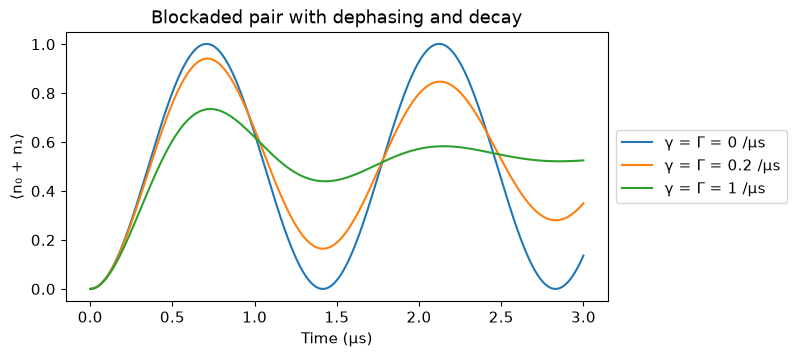

In [6]:
pair = [(0.0, 0.0), (5e-6, 0.0)]
for rate in (0.0, 0.2e6, 1e6):  # per second
    noise = [math.sqrt(rate) * op(i) for i in range(2) for op in (number, boson.annihilate)] if rate else []
    result = simulate(pair, **drive, observables=[number(0) + number(1)], collapse_operators=noise)
    excitations = [step[0].expectation() for step in result.expectation_values()]
    plt.plot(grid, excitations, label=f"γ = Γ = {rate / 1e6:g} /µs")
plt.xlabel("Time (µs)")
plt.ylabel("⟨n₀ + n₁⟩")
plt.title("Blockaded pair with dephasing and decay")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()

The oscillations damp and drift towards a mixed state: this is why a physical QPU gives a less sharp blockade and a lower MIS success rate than the ideal emulator.

## Key points

- The `dynamics` target evolves any Hamiltonian you build from CUDA-Q operators: `spin.x`, `spin.y`, `number`, products and sums with time-dependent `ScalarOperator` coefficients.
- To match the `pasqal` backend, reproduce its pulse semantics (linear Ω and Δ, held φ), its $C_6$ and its atom-order bitstrings.
- `evolve` returns states and stored expectation values, so one run gives the whole time trace.
- Collapse operators turn it into a noisy, open-system simulator.

The cost: a state vector holds $2^N$ amplitudes, a density matrix $4^N$. cuDensityMat can spread larger problems over several GPUs; see CUDA-Q's [dynamics documentation](https://nvidia.github.io/cuda-quantum/latest/using/backends/dynamics.html).

<div class="alert alert-success">

**To go further**

- Run the MIS anneal of notebook 2 with dephasing. How fast does P(optimal) drop with $\gamma$?
- Add a site-dependent detuning term $-\delta_i(t)\, n_i$, which the `pasqal` target does not accept, and use it to favour one of the two MIS optima.
- Time `simulate` for 4 to 10 atoms, with and without noise.

</div>